<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/04_Multi_Classifications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

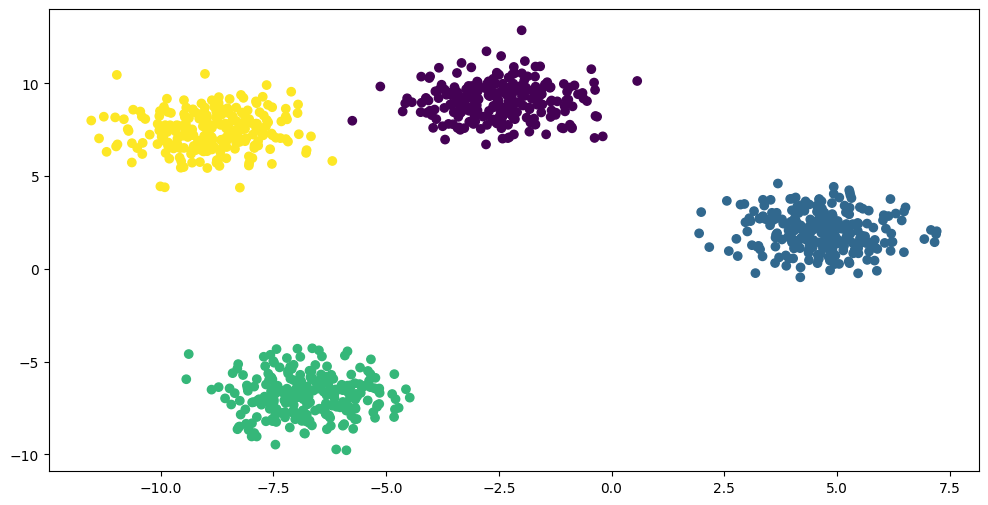

In [6]:
num_class=4
num_features=2
random_seed=42
x_blobs,y_blobs=make_blobs(n_samples=1000,n_features=num_features,centers=num_class,cluster_std=1,random_state=random_seed)
x_blobs_train,x_blobs_test,y_blobs_train,y_blobs_test=train_test_split(x_blobs,y_blobs,test_size=0.2,random_state=random_seed)
plt.figure(figsize=(12,6))
plt.scatter(x_blobs[:,0],x_blobs[:,1],c=y_blobs)


In [12]:
device='cuda' if torch.cuda.is_available() else 'cpu'
from torch import nn
class Blobmodel(nn.Module):
  def __init__(self,input_feauters:int,output_featers:int,hidden_layers:int=8):
    super().__init__()
    self.linear_layer_stick=(nn.Sequential(
        nn.Linear(in_features=input_feauters,out_features=hidden_layers),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layers,out_features=hidden_layers),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layers,out_features=output_featers)

    ))
  def forward(self,x:torch.tensor)->torch.tensor:
    return self.linear_layer_stick(x)
model_3= Blobmodel(input_feauters=num_features,output_featers=num_class).to(device)


In [14]:
loss_fn=nn.CrossEntropyLoss()
optomizier=torch.optim.SGD(params=model_3.parameters(),lr=0.1)